# Part 3 — Scalable Processing
## Notebook 04. Comparable FDIC transformations in pandas, Polars and PySpark

**Research objective.** Evaluate the execution behaviour, numerical equivalence and scaling of three analytically distinct transformations on the verified FDIC bank-quarter panel. Compare pandas eager execution with Polars LazyFrame and PySpark local SQL execution. Measure from the same staged Parquet files on the Colab local disk.

**Source contract.** An existing Google Drive experiment must contain verified `acquisition`, `storage` and `quality_panel` stages. The stage is resolved by `experiment_manifest.json`, not by directory age or a hard-coded historical run ID. All earlier stages remain read-only.

**Outputs.** Controlled measured trials; full cross-engine row/value checks; six execution plans; independently verified medians; plots; source SHA-256 provenance and immutable `processing` handoff.

**Interpretation boundary.** Spark uses `local[2]` on one Colab machine, not a multi-node cluster. No future failure outcomes or retrospective institutional-exit fields are included in the transformations.


### 1. Restore the selected experiment and processing source revision

The experiment preserves the acquisition source revision and the quality-panel revision independently. If Part 3 is already published, its own source commit is restored before execution. Otherwise, the current repository commit is used and recorded as the Part 3 source revision. Dependencies are installed from pinned files; packages already satisfying the requirement are not forcibly reinstalled.


In [1]:
from pathlib import Path
import json, re, shutil, subprocess, sys
from google.colab import drive

drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive/BFT65B_11230945')
active_path = DRIVE_ROOT / 'control' / 'active_experiment.json'
assert active_path.is_file(), 'Complete Notebooks 01–03 first'
EXPERIMENT_ID = json.loads(active_path.read_text(encoding='utf-8'))['experiment_id']
EXPERIMENT_DIR = DRIVE_ROOT / 'experiments' / EXPERIMENT_ID
PART1_COMMIT = json.loads((EXPERIMENT_DIR/'experiment_config.lock.json').read_text())['git_commit']
QUALITY_MANIFEST = json.loads((EXPERIMENT_DIR/'quality_panel'/'part2_manifest.json').read_text())
PART2_COMMIT = QUALITY_MANIFEST['code_commit']

REPO_DIR = Path('/content/bft65b_code')
if REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)
subprocess.run(['git','clone','--quiet',
    'https://github.com/NguyenDuong58/11230945-NguyenBaDuong.git',str(REPO_DIR)], check=True)
part3_manifest = EXPERIMENT_DIR/'processing'/'part3_manifest.json'
if part3_manifest.is_file():
    PART3_COMMIT = json.loads(part3_manifest.read_text())['code_commit']
    assert re.fullmatch(r'[0-9a-f]{40}', PART3_COMMIT)
    subprocess.run(['git','-C',str(REPO_DIR),'checkout','--quiet',PART3_COMMIT],check=True)
else:
    PART3_COMMIT = subprocess.check_output(
        ['git','-C',str(REPO_DIR),'rev-parse','HEAD'],text=True).strip()
assert subprocess.check_output(
    ['git','-C',str(REPO_DIR),'rev-parse','HEAD'],text=True).strip() == PART3_COMMIT
subprocess.run([sys.executable,'-m','pip','install','-q','-r',
                str(REPO_DIR/'requirements_part3.txt')],check=True)
# Avoid stale modules if a previous notebook ran in this same Python runtime.
for name in list(sys.modules):
    if name == 'fdic_pipeline' or name.startswith('fdic_pipeline.'):
        del sys.modules[name]
sys.path.insert(0,str(REPO_DIR/'src'))
print('Experiment:',EXPERIMENT_ID)
print('Acquisition commit:',PART1_COMMIT)
print('Quality-panel commit:',PART2_COMMIT)
print('Processing commit:',PART3_COMMIT)


Mounted at /content/drive
Experiment: experiment_20261116T115513Z_d23d2b10
Acquisition commit: c5bad10b9199fe163ae7e1e1c1d9029a4be0c470
Quality-panel commit: 68751e16b01fc7d984ed8c918dd059277830a105
Processing commit: 58d5f1ad37e5f14a30618f49a6ec9e063c0a8fcd


### 2. Verify installed engines and run the complete test suite

The verification gate includes all Parts 1–3 tests and Parquet integration checks that execute pandas, Polars and PySpark on identical synthetic reporting histories. The notebook stops if any test fails, errors, or is skipped. Spark 4.0.1 requires Java 17 or later.


In [2]:
import importlib.metadata
import xml.etree.ElementTree as ET

for package in ('pandas','polars','pyspark','pyarrow','psutil'):
    print(package, importlib.metadata.version(package))
java_version = subprocess.run(['java','-version'],capture_output=True,text=True,check=True).stderr
print(java_version.splitlines()[0])
assert re.search(r'version "(?:17|18|19|2[0-9])',java_version), 'Java 17+ is required'
TEST_XML = Path('/content/bft65b_part3_tests.xml')
subprocess.run([sys.executable,'-m','pytest','-q','-rs','--junitxml',str(TEST_XML),
                str(REPO_DIR/'tests')],cwd=REPO_DIR,check=True)
suites = ET.parse(TEST_XML).getroot().findall('.//testsuite')
assert suites, 'No test suites were recorded'
result={key:sum(int(item.get(key,0)) for item in suites)
        for key in ('tests','failures','errors','skipped')}
assert result['failures']==result['errors']==result['skipped']==0, result
print('Full Parts 1–3 test gate: PASSED',result)


pandas 2.2.3
polars 1.35.2
pyspark 4.0.1
pyarrow 21.0.0
psutil 7.0.0
openjdk version "21.0.12.1" 2026-08-18
Full Parts 1–3 test gate: PASSED {'tests': 150, 'failures': 0, 'errors': 0, 'skipped': 0}


### 3. Verify acquisition, storage and quality-panel lineage

The controller rejects a changed parent validation hash, missing quarter, changed source SHA-256, incompatible schema, or retrospective target field. The 48-column clean panel is the only computational input; failure-linkage and terminal-exit audit tables are excluded.


In [3]:
from fdic_pipeline.project_flow import get_active, resolve_stage, stage_dir
from fdic_pipeline.scalable_processing import input_contract
ACTIVE=get_active(DRIVE_ROOT)
assert ACTIVE['experiment_id']==EXPERIMENT_ID
for stage in ('acquisition','storage','quality_panel'):
    assert resolve_stage(DRIVE_ROOT,stage)['status']=='PASSED'
SNAP=input_contract(DRIVE_ROOT,check_data_hashes=True)
assert SNAP['panel_fields']==48
assert len(SNAP['partitions'])==170
assert SNAP['part2_commit']==PART2_COMMIT
assert SNAP['samples']['full_170']['rows']==SNAP['panel_rows']
assert SNAP['samples']['recent_85']['quarters']==85
print('Source input contract: PASSED')
print('Panel rows:',SNAP['panel_rows'])
print('Schema fields:',SNAP['panel_fields'])
print('Sample definitions:',SNAP['samples'])
print('Quality-stage validation SHA-256:',SNAP['quality_verification_sha256'])


Source input contract: PASSED
Panel rows: 1682616
Schema fields: 48
Sample definitions: {'recent_85': {'quarters': 85, 'rows': 550011, 'first': '20050630', 'last': '20260630'}, 'full_170': {'quarters': 170, 'rows': 1682616, 'first': '19840331', 'last': '20260630'}}
Quality-stage validation SHA-256: 43aed148645d68e0301388a6bfdc752a77ead9cebcf23405757685eef86b94b5


### 4. Prespecify analytical workloads, engines and measurement rules

**W1 — Quarter aggregation.** Aggregate the six selected source fields for observations from 2000Q1: bank-quarter count, total assets, total deposits, mean ROA and the count of extreme-ROE flags.

**W2 — Adjacent-quarter asset growth.** Sort observations by CERT and REPDTE; compute lagged assets within the same CERT; calculate percentage growth **only when the prior observed report is exactly one quarter earlier**; aggregate the number of valid adjacent pairs and their mean growth by reporting date.

**W3 — State-year risk aggregation.** Group by reporting year and source state abbreviation; aggregate assets, gross loans, mean ROA, negative-equity indicators, loan-exposure flags and the number of reports with any missing financial field. Source-null state labels are grouped under `MISSING`.

**Scales.** The latest 85 reporting quarters and all 170 reporting quarters; neither synthetic replication nor sampling with replacement is used. As the institution population changes over time, size effects are observational, not a pure controlled input-row elasticity.

**Timing.** One warmup and five measured repetitions per engine–workload–scale combination, seeded randomized order and fresh worker processes. Engine initialization is excluded; local Parquet reads, transformations and result materialization are timed. Process-tree RSS is sampled at approximately 50 ms intervals, including the Spark JVM. All engines read the same `/content` Parquet snapshot and use the same projection and filter definitions.


In [4]:
from fdic_pipeline.processing_engines import ENGINE_NAMES,WORKLOADS,PARQUET_COLS
from fdic_pipeline.scalable_processing import DEFAULT_REPETITIONS,DEFAULT_WARMUPS,SAMPLE_NAMES
REPETITIONS=DEFAULT_REPETITIONS
WARMUPS=DEFAULT_WARMUPS
SEED=11230945
assert len(WORKLOADS)==3 and len(ENGINE_NAMES)==3 and len(SAMPLE_NAMES)==2
assert REPETITIONS>=3 and WARMUPS>=1
print('Engines:',ENGINE_NAMES)
print('Workloads:',WORKLOADS)
for w in WORKLOADS:
    print(w,'requires',PARQUET_COLS[w])
print('Expected measured trials:',len(ENGINE_NAMES)*len(WORKLOADS)*len(SAMPLE_NAMES)*REPETITIONS)
print('Expected warmups:',len(ENGINE_NAMES)*len(WORKLOADS)*len(SAMPLE_NAMES)*WARMUPS)
print('Expected cross-engine parity comparisons:',2*len(WORKLOADS)*len(SAMPLE_NAMES)*(WARMUPS+REPETITIONS))


Engines: ('pandas', 'polars', 'pyspark')
Workloads: ('quarter_aggregation', 'adjacent_asset_growth', 'state_year_risk')
quarter_aggregation requires ('CERT', 'REPDTE', 'ASSET', 'DEP', 'ROA', 'DQ_EXTREME_ROE')
adjacent_asset_growth requires ('CERT', 'REPDTE', 'ASSET')
state_year_risk requires ('CERT', 'REPDTE', 'STNAME', 'ASSET', 'LNLSGR', 'ROA', 'DQ_NEGATIVE_EQUITY', 'DQ_GROSS_LOANS_GT_ASSETS', 'MISSING_FINANCIAL_COUNT')
Expected measured trials: 90
Expected warmups: 18
Expected cross-engine parity comparisons: 72


### 5. Run the controlled benchmark and publish the processing stage

The driver copies checksum-validated panel partitions to local scratch and creates an 85-quarter subset using hard links where available. Each trial runs in a separate Python process. A full pandas–Polars and pandas–PySpark value-level comparison is required for each workload, scale and repetition, including warmups. No stage is published when comparisons disagree.

Results are written under `experiments/<experiment_id>/processing/` and sealed by SHA-256 after independent evidence verification. If the run is interrupted before publication, rerunning this section rebuilds only the incomplete processing stage; acquisition, storage and quality-panel outputs remain untouched.


In [5]:
from fdic_pipeline.project_flow import HandoffError
PROCESSING_DIR=stage_dir(DRIVE_ROOT,'processing')
SCRATCH=Path('/content')/('bft65b_p3_'+EXPERIMENT_ID)
LOG_FILE=EXPERIMENT_DIR/'run_logs'/'part3_scalable_processing.log'
try:
    PREVIOUS=resolve_stage(DRIVE_ROOT,'processing')
except HandoffError as exc:
    if 'has not passed verification' not in str(exc):
        raise
    PREVIOUS=None
if PREVIOUS is None:
    free_gib=shutil.disk_usage('/content').free/(2**30)
    assert free_gib >= 3.0, f'At least 3 GiB local disk space required: {free_gib:.2f} GiB available'
    command=[sys.executable,'-u',str(REPO_DIR/'run_scalable_processing.py'),'build',
             '--drive-root',str(DRIVE_ROOT),'--code-commit',PART3_COMMIT,
             '--scratch',str(SCRATCH),'--repetitions',str(REPETITIONS),
             '--warmups',str(WARMUPS),'--replace-incomplete','--log-file',str(LOG_FILE)]
    subprocess.run(command,cwd=REPO_DIR,check=True)
else:
    print('Processing stage already published; running read-only verification')
print('Processing evidence directory:',PROCESSING_DIR)
print('Persistent log:',LOG_FILE)


Processing evidence directory: /content/drive/MyDrive/BFT65B_11230945/experiments/experiment_20261116T115513Z_d23d2b10/processing
Persistent log: /content/drive/MyDrive/BFT65B_11230945/experiments/experiment_20261116T115513Z_d23d2b10/run_logs/part3_scalable_processing.log


### 6. Inspect the measured engine comparison and sample scaling

Median times are calculated independently from recorded trials. Speedup is defined as pandas median elapsed time divided by the comparison engine median for the same workload and sample. A value above one indicates a faster comparison engine. The full/recent scaling ratio is not a fixed-row growth law because institution counts differ across periods.


In [6]:
import csv
from IPython.display import display, Markdown

def show_csv(title, rel, limit=25):
    with (PROCESSING_DIR/rel).open(newline='',encoding='utf-8') as f:
        rows=list(csv.DictReader(f))
    display(Markdown('**'+title+'**'))
    assert rows, f'Empty evidence file: {rel}'
    fields=list(rows[0])
    rows=rows[:limit]
    display(Markdown(' | '.join(fields)+'\n'+' | '.join(['---']*len(fields))+'\n'+
      '\n'.join(' | '.join(str(row[k]) for k in fields) for row in rows)))

show_csv('Measured run medians and speedups','performance_summary.csv',18)
show_csv('Observed full/recent scaling','scaling_summary.csv',9)
show_csv('Cross-engine equivalence checks (first 12)','equivalence.csv',12)


**Measured run medians and speedups**

sample | workload | engine | runs | median_seconds | median_peak_process_tree_rss_mib | pandas_over_engine_speedup | output_rows
--- | --- | --- | --- | --- | --- | --- | ---
recent_85 | quarter_aggregation | pandas | 5 | 0.9005978549998872 | 255.3671875 | 1.0 | 85
recent_85 | quarter_aggregation | polars | 5 | 0.22079316399992877 | 105.90234375 | 4.078920917135721 | 85
recent_85 | quarter_aggregation | pyspark | 5 | 16.174005008999984 | 714.58984375 | 0.0556818088345312 | 85
recent_85 | adjacent_asset_growth | pandas | 5 | 1.4533426830000735 | 255.0078125 | 1.0 | 85
recent_85 | adjacent_asset_growth | polars | 5 | 0.405548614999816 | 142.41796875 | 3.583646027248134 | 85
recent_85 | adjacent_asset_growth | pyspark | 5 | 20.493049735999875 | 843.15234375 | 0.07091880914371691 | 85
recent_85 | state_year_risk | pandas | 5 | 1.3051940709999599 | 319.23828125 | 1.0 | 1238
recent_85 | state_year_risk | polars | 5 | 0.3305758279998372 | 195.125 | 3.9482441257035967 | 1238
recent_85 | state_year_risk | pyspark | 5 | 16.26932756500014 | 730.83203125 | 0.08022421736764317 | 1238
full_170 | quarter_aggregation | pandas | 5 | 1.0754458440001144 | 302.56640625 | 1.0 | 106
full_170 | quarter_aggregation | polars | 5 | 0.4062987820000217 | 112.0625 | 2.6469334677947844 | 106
full_170 | quarter_aggregation | pyspark | 5 | 21.037726239999984 | 731.76171875 | 0.05111987064245187 | 106
full_170 | adjacent_asset_growth | pandas | 5 | 1.8328177040000355 | 473.796875 | 1.0 | 170
full_170 | adjacent_asset_growth | polars | 5 | 1.0137314450000758 | 251.0859375 | 1.8079913699430508 | 170
full_170 | adjacent_asset_growth | pyspark | 5 | 28.186482730999842 | 1015.37109375 | 0.06502470427018835 | 170
full_170 | state_year_risk | pandas | 5 | 3.3479458469998917 | 631.7890625 | 1.0 | 2430
full_170 | state_year_risk | polars | 5 | 0.7257664720000321 | 431.4375 | 4.612979486051188 | 2430
full_170 | state_year_risk | pyspark | 5 | 20.0894492540001 | 742.97265625 | 0.16665194772988948 | 2430

**Observed full/recent scaling**

engine | workload | recent_85_median_seconds | full_170_median_seconds | full_over_recent_runtime_ratio
--- | --- | --- | --- | ---
pandas | quarter_aggregation | 0.9005978549998872 | 1.0754458440001144 | 1.194146574999614
pandas | adjacent_asset_growth | 1.4533426830000735 | 1.8328177040000355 | 1.2611049860702004
pandas | state_year_risk | 1.3051940709999599 | 3.3479458469998917 | 2.565094280910195
polars | quarter_aggregation | 0.22079316399992877 | 0.4062987820000217 | 1.8401782674764005
polars | adjacent_asset_growth | 0.405548614999816 | 1.0137314450000758 | 2.4996545605279303
polars | state_year_risk | 0.3305758279998372 | 0.7257664720000321 | 2.19546140560643
pyspark | quarter_aggregation | 16.174005008999984 | 21.037726239999984 | 1.300712237216051
pyspark | adjacent_asset_growth | 20.493049735999875 | 28.186482730999842 | 1.375416694640867
pyspark | state_year_risk | 16.26932756500014 | 20.0894492540001 | 1.2348051370738953

**Cross-engine equivalence checks (first 12)**

iteration | warmup | sample | workload | comparison | rows_compared | max_absolute_difference
--- | --- | --- | --- | --- | --- | ---
-1 | True | recent_85 | quarter_aggregation | pandas_vs_polars | 85 | 6.217248937900877e-15
-1 | True | recent_85 | quarter_aggregation | pandas_vs_pyspark | 85 | 6.217248937900877e-15
-1 | True | recent_85 | adjacent_asset_growth | pandas_vs_polars | 85 | 4.085620730620576e-14
-1 | True | recent_85 | adjacent_asset_growth | pandas_vs_pyspark | 85 | 1.9539925233402755e-14
-1 | True | recent_85 | state_year_risk | pandas_vs_polars | 1238 | 0.0
-1 | True | recent_85 | state_year_risk | pandas_vs_pyspark | 1238 | 5.329070518200751e-15
-1 | True | full_170 | quarter_aggregation | pandas_vs_polars | 106 | 6.217248937900877e-15
-1 | True | full_170 | quarter_aggregation | pandas_vs_pyspark | 106 | 6.439293542825908e-15
-1 | True | full_170 | adjacent_asset_growth | pandas_vs_polars | 170 | 0.0
-1 | True | full_170 | adjacent_asset_growth | pandas_vs_pyspark | 170 | 4.796163466380676e-14
-1 | True | full_170 | state_year_risk | pandas_vs_polars | 2430 | 0.0
-1 | True | full_170 | state_year_risk | pandas_vs_pyspark | 2430 | 8.881784197001252e-15

### 7. Inspect optimized Polars and Spark plans

The Polars plans are generated with `LazyFrame.explain(optimized=True)`; the Spark plans contain analyzed, optimized and physical plan information from query execution. Look for Parquet scans, projection, filter pushdown, aggregation, sorting, window operations and Spark exchanges. Plan-inspection indicators are recorded as string matches and must not be presented as proof that a particular optimization occurred without reading the plan.


In [7]:
show_csv('Execution-plan inspection','plan_inspection.csv',6)
for path in ('plans/polars_adjacent_asset_growth.txt',
             'plans/pyspark_adjacent_asset_growth.txt'):
    content=(PROCESSING_DIR/path).read_text(encoding='utf-8')
    display(Markdown('**'+path+' — first 35 lines**'))
    display(Markdown('```text\n'+'\n'.join(content.splitlines()[:35])+'\n```'))
print('All 6 complete plan files and the interpretation guide are preserved on Drive')


**Execution-plan inspection**

engine | workload | plan_file | plan_sha256 | plan_characters | contains_scan | contains_filter | contains_aggregate | contains_sort | contains_window | contains_exchange_or_shuffle
--- | --- | --- | --- | --- | --- | --- | --- | --- | --- | ---
polars | quarter_aggregation | plans/polars_quarter_aggregation.txt | 2f2b365551f3c451ca2afd3685f9c2c93ae346df66935261fb0f9dde614d8a64 | 571 | 1 | 0 | 1 | 1 | 0 | 0
pyspark | quarter_aggregation | plans/pyspark_quarter_aggregation.txt | 4d95ae31eb91d20f32641240d9c7158a6cd15f0e3b1fec18658e837987034f89 | 3719 | 1 | 1 | 1 | 1 | 0 | 1
polars | adjacent_asset_growth | plans/polars_adjacent_asset_growth.txt | e90acd9871e5b024babe858d2cd597d1ef4b331aa85438b87e8d50ae323d1887 | 1230 | 1 | 0 | 1 | 1 | 1 | 0
pyspark | adjacent_asset_growth | plans/pyspark_adjacent_asset_growth.txt | 1be9358c190c276b09217100e9bdf0ab343d27cfb3cac3678a5cba917056972d | 7600 | 1 | 1 | 1 | 1 | 1 | 1
polars | state_year_risk | plans/polars_state_year_risk.txt | 2b5b421b4394a624ee6f317ade1dba266761a36dc7b304954ea25fbf4b3162e9 | 1016 | 1 | 0 | 1 | 1 | 0 | 0
pyspark | state_year_risk | plans/pyspark_state_year_risk.txt | eaf9b79a2fa2e029086ee44fe22f5775ca56edd3e13dfcdc4c248e56cd979689 | 6503 | 1 | 1 | 1 | 1 | 0 | 1

**plans/polars_adjacent_asset_growth.txt — first 35 lines**

```text
SORT BY [col("REPDTE")]
  AGGREGATE[maintain_order: false]
    [len().alias("BANK_QUARTERS"), col("_ADJ").strict_cast(Int64).sum().alias("CONSECUTIVE_PAIRS"), col("_GROWTH").mean().alias("MEAN_ASSET_GROWTH_PCT")] BY [col("REPDTE")]
    FROM
     WITH_COLUMNS:
     [when([(col("_ADJ")) & ([(col("_PREV_ASSET")) > (0.0)])]).then([(100.0) * ([([(col("ASSET")) / (col("_PREV_ASSET"))]) - (1.0)])]).otherwise(null.cast(Float64)).alias("_GROWTH")] 
       WITH_COLUMNS:
       [[([(col("_Q")) - (col("_PREV_Q"))]) == (1)].fill_null([false]).alias("_ADJ")] 
        simple π 6/6 ["CERT", "REPDTE", "ASSET", ... 3 other columns]
           WITH_COLUMNS:
           [col("_Q").shift([dyn int: 1]).over([col("CERT")]).alias("_PREV_Q")] 
             WITH_COLUMNS:
             [[([(col("REPDTE").dt.year()) * (4)]) + (col("REPDTE").dt.quarter().cast(Int32))].alias("_Q"), col("ASSET").shift([dyn int: 1]).over([col("CERT")]).alias("_PREV_ASSET")] 
              SORT BY [col("CERT"), col("REPDTE")]
                Parquet SCAN [/content/bft65b_p3_experiment_20261116T115513Z_d23d2b10/full_170/panel/year=1984/quarter=1/part-00000.parquet, ... 169 other sources]
                PROJECT 3/48 COLUMNS
                ESTIMATED ROWS: 3048100
```

**plans/pyspark_adjacent_asset_growth.txt — first 35 lines**

```text
== Parsed Logical Plan ==
'Sort ['REPDTE ASC NULLS FIRST], true
+- Aggregate [REPDTE#80], [REPDTE#80, count(1) AS BANK_QUARTERS#135L, sum(_ADJ#133) AS CONSECUTIVE_PAIRS#136L, avg(_GROWTH#134) AS MEAN_ASSET_GROWTH_PCT#137]
   +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131, _PREV_ASSET#132, _ADJ#133, CASE WHEN ((_ADJ#133 = 1) AND (_PREV_ASSET#132 > cast(0 as double))) THEN (((ASSET#82 / _PREV_ASSET#132) - 1.0) * 100.0) END AS _GROWTH#134]
      +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131, _PREV_ASSET#132, CASE WHEN ((_Q#130 - _PREV_Q#131) = 1) THEN 1 ELSE 0 END AS _ADJ#133]
         +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131, _PREV_ASSET#132]
            +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131, _PREV_ASSET#132, _PREV_ASSET#132]
               +- Window [lag(ASSET#82, -1, null) windowspecdefinition(CERT#79L, REPDTE#80 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -1, -1)) AS _PREV_ASSET#132], [CERT#79L], [REPDTE#80 ASC NULLS FIRST]
                  +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131]
                     +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131]
                        +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131, _PREV_Q#131]
                           +- Window [lag(_Q#130, -1, null) windowspecdefinition(CERT#79L, REPDTE#80 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -1, -1)) AS _PREV_Q#131], [CERT#79L], [REPDTE#80 ASC NULLS FIRST]
                              +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130]
                                 +- Project [CERT#79L, REPDTE#80, ASSET#82, ((year(REPDTE#80) * 4) + quarter(REPDTE#80)) AS _Q#130]
                                    +- Project [CERT#79L, REPDTE#80, ASSET#82]
                                       +- Relation [CERT#79L,REPDTE#80,STNAME#81,ASSET#82,DEP#83,DEPDOM#84,EQ#85,BRO#86,CHBAL#87,SC#88,LNLSGR#89,LNLSNET#90,LNRE#91,LNCI#92,LNCON#93,LNATRES#94,NCLNLS#95,P3ASSET#96,P9ASSET#97,NAASSET#98,NTLNLS#99,ORE#100,NETINC#101,INTINC#102,EINTEXP#103,... 25 more fields] parquet

== Analyzed Logical Plan ==
REPDTE: date, BANK_QUARTERS: bigint, CONSECUTIVE_PAIRS: bigint, MEAN_ASSET_GROWTH_PCT: double
Sort [REPDTE#80 ASC NULLS FIRST], true
+- Aggregate [REPDTE#80], [REPDTE#80, count(1) AS BANK_QUARTERS#135L, sum(_ADJ#133) AS CONSECUTIVE_PAIRS#136L, avg(_GROWTH#134) AS MEAN_ASSET_GROWTH_PCT#137]
   +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131, _PREV_ASSET#132, _ADJ#133, CASE WHEN ((_ADJ#133 = 1) AND (_PREV_ASSET#132 > cast(0 as double))) THEN (((ASSET#82 / _PREV_ASSET#132) - 1.0) * 100.0) END AS _GROWTH#134]
      +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131, _PREV_ASSET#132, CASE WHEN ((_Q#130 - _PREV_Q#131) = 1) THEN 1 ELSE 0 END AS _ADJ#133]
         +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131, _PREV_ASSET#132]
            +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131, _PREV_ASSET#132, _PREV_ASSET#132]
               +- Window [lag(ASSET#82, -1, null) windowspecdefinition(CERT#79L, REPDTE#80 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -1, -1)) AS _PREV_ASSET#132], [CERT#79L], [REPDTE#80 ASC NULLS FIRST]
                  +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131]
                     +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131]
                        +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130, _PREV_Q#131, _PREV_Q#131]
                           +- Window [lag(_Q#130, -1, null) windowspecdefinition(CERT#79L, REPDTE#80 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -1, -1)) AS _PREV_Q#131], [CERT#79L], [REPDTE#80 ASC NULLS FIRST]
                              +- Project [CERT#79L, REPDTE#80, ASSET#82, _Q#130]
                                 +- Project [CERT#79L, REPDTE#80, ASSET#82, ((year(REPDTE#80) * 4) + quarter(REPDTE#80)) AS _Q#130]
                                    +- Project [CERT#79L, REPDTE#80, ASSET#82]
                                       +- Relation [CERT#79L,REPDTE#80,STNAME#81,ASSET#82,DEP#83,DEPDOM#84,EQ#85,BRO#86,CHBAL#87,SC#88,LNLSGR#89,LNLSNET#90,LNRE#91,LNCI#92,LNCON#93,LNATRES#94,NCLNLS#95,P3ASSET#96,P9ASSET#97,NAASSET#98,NTLNLS#99,ORE#100,NETINC#101,INTINC#102,EINTEXP#103,... 25 more fields] parquet

```

All 6 complete plan files and the interpretation guide are preserved on Drive


### 8. Display controlled benchmark figures

Figures are generated only from measured trials and are stored with SHA-256 evidence. Runtime plots should be interpreted alongside the exact workload, sample, CPU environment, and process memory protocol.


**Median Runtime**

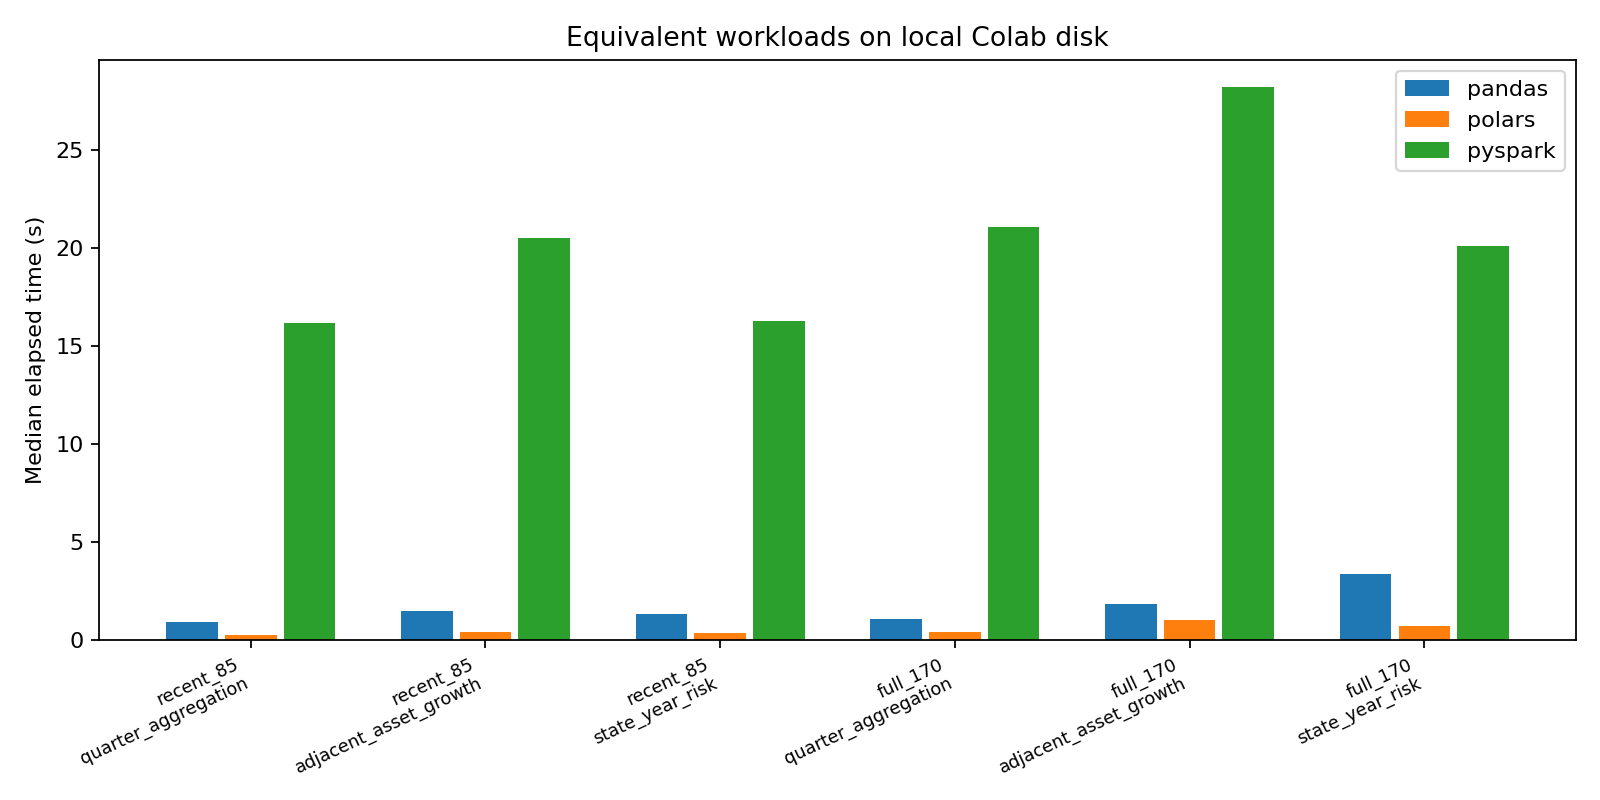

**Scaling**

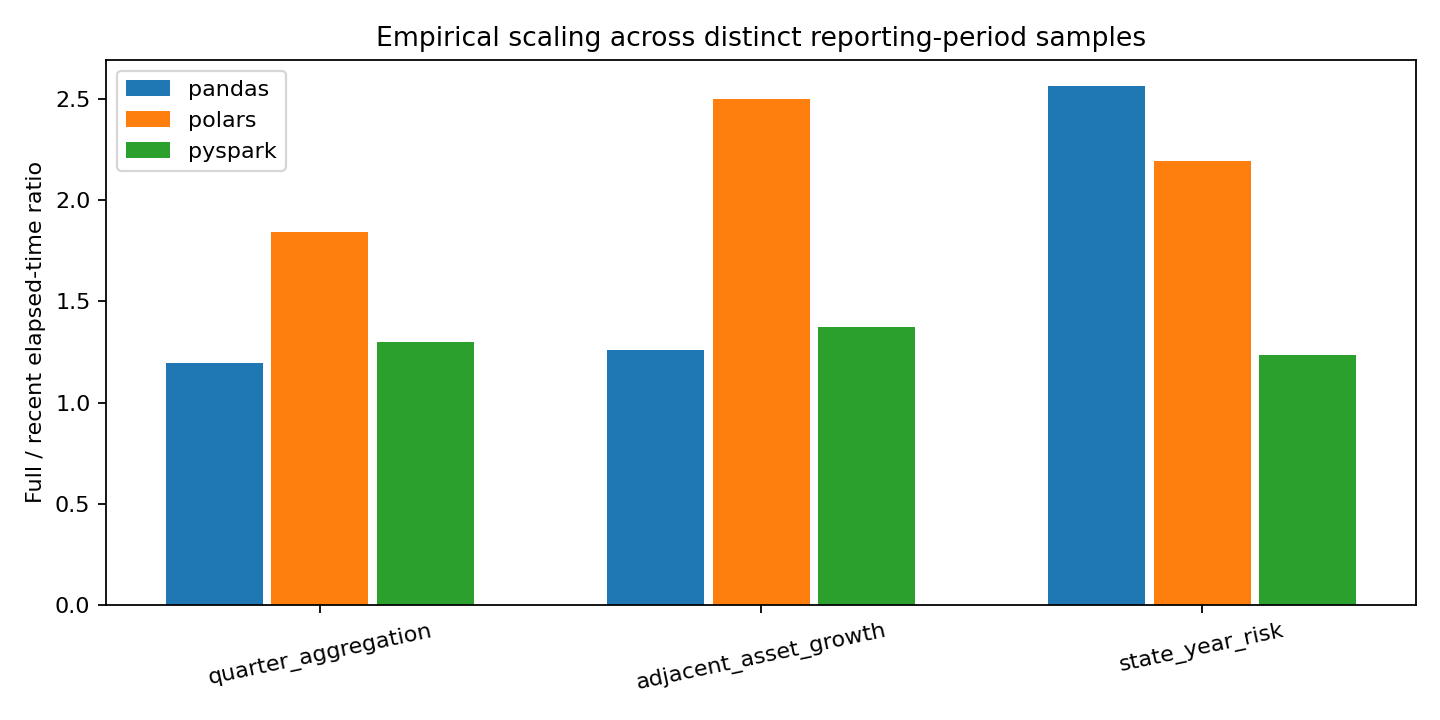

**Median Process Rss**

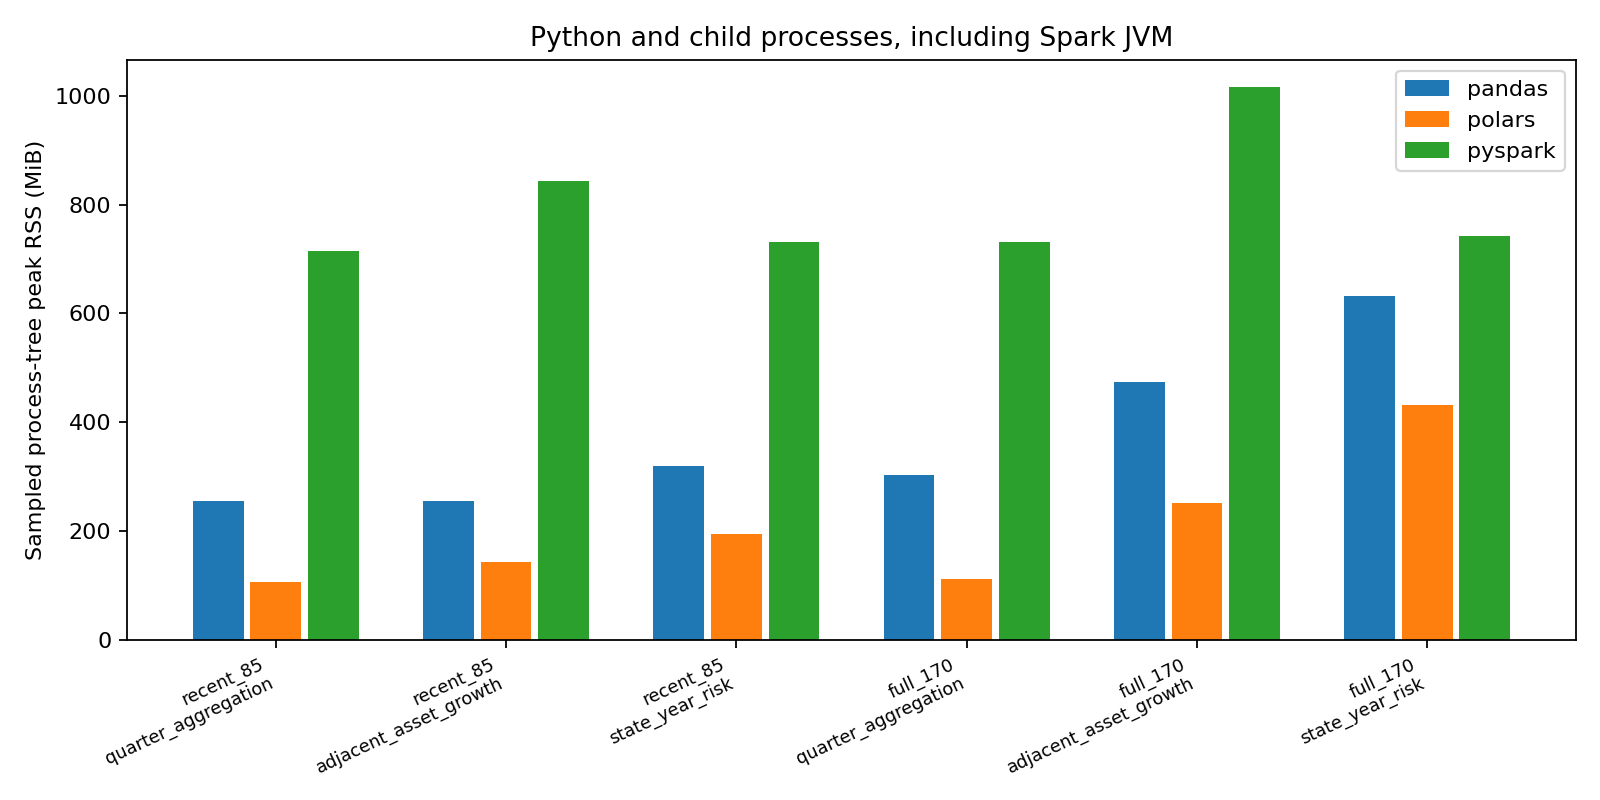

In [8]:
from IPython.display import Image
for name in ('figures/median_runtime.png',
             'figures/scaling.png','figures/median_process_rss.png'):
    display(Markdown('**'+Path(name).stem.replace('_',' ').title()+'**'))
    display(Image(filename=str(PROCESSING_DIR/name),width=850))


### 9. Independently verify the published Part 3 evidence

The verification step rechecks all upstream stage references, SHA-256 of the 170 source partitions, every evidence file and execution plan, the completeness of each measurement round, the number of numerical comparisons and the median/ratio arithmetic. The stage and its parent-validation references are immutable after publication.


In [9]:
from fdic_pipeline.scalable_processing import verify_project_stage
VERIFIED=verify_project_stage(DRIVE_ROOT)
assert VERIFIED['success'] is True
assert VERIFIED['source_quarters']==170
assert VERIFIED['panel_rows']==SNAP['panel_rows']
assert VERIFIED['measured_trials']==90
assert VERIFIED['warmup_trials']==18
assert VERIFIED['numerical_comparisons']==72
assert VERIFIED['plan_files']==6
assert VERIFIED['cluster_tested'] is False
print('Part 3: PASSED')
for key in ('panel_rows','measured_trials','warmup_trials',
            'numerical_comparisons','plan_files','evidence_artifacts_verified'):
    print(key+':',VERIFIED[key])
print('Verified source-to-output lineage: PASSED')


Part 3: PASSED
panel_rows: 1682616
measured_trials: 90
warmup_trials: 18
numerical_comparisons: 72
plan_files: 6
evidence_artifacts_verified: 24
Verified source-to-output lineage: PASSED


### 10. Establish the processing evidence contract for Parts 4–6

Part 4 uses the verified `quality_panel/panel/` as the input for point-in-time feature engineering. It may reference the `processing` stage for measurement provenance, but must not use computed aggregate summaries as contemporaneous bank-level predictors, nor read retrospective failure/exit audit fields as predictors. Part 5 will operate on separately constructed labels and modelling samples.


In [10]:
STAGE=resolve_stage(DRIVE_ROOT,'processing')
assert STAGE['status']=='PASSED'
assert STAGE['validation']['part3_manifest_sha256']==VERIFIED['part3_manifest_sha256']
assert STAGE['parent_verification_sha256']==SNAP['quality_verification_sha256']
print('Part 4 panel source:',Path(resolve_stage(DRIVE_ROOT,'quality_panel')['path'])/'panel')
print('Part 3 evidence:',PROCESSING_DIR)
print('Processing code commit:',VERIFIED['code_commit'])
print('Handoff state: PASSED')


Part 4 panel source: /content/drive/MyDrive/BFT65B_11230945/experiments/experiment_20261116T115513Z_d23d2b10/quality_panel/panel
Part 3 evidence: /content/drive/MyDrive/BFT65B_11230945/experiments/experiment_20261116T115513Z_d23d2b10/processing
Processing code commit: 58d5f1ad37e5f14a30618f49a6ec9e063c0a8fcd
Handoff state: PASSED
